# Simulated SBS mutational catalogues for Wasserstein NMF (Section 3.1)

This notebook reproduces the data generation described in **Section 3.1** of the report
*"Wasserstein NMF for Mutational Signatures"*, producing the 9 experimental datasets used in Section 4:

| | 2 % noise | 4 % noise | 6 % noise |
|---|---|---|---|
| **8 signatures** | ✓ | ✓ | ✓ |
| **15 signatures** | ✓ | ✓ | ✓ |
| **25 signatures** | ✓ | ✓ | ✓ |

**Generative process (as in the report)**

1. Source signatures: COSMIC v3.4 SBS (96 trinucleotide channels). The first *n* of the report's
   orthogonality-ranked list of 25 signatures are used (SBS5 and SBS40 excluded).
2. Total SBS count per sample: uniform on the **log scale** between a min and a max, set manually or from
   a cancer type with high / medium / low mutational burden (Skin-Melanoma / Biliary-AdenoCA / Thy-AdenoCA).
3. Each signature is present in a sample with a fixed probability *p* (expected signatures per sample = *n·p*).
4. Contribution of each present signature: uniform distribution (normalised to sum to 1 per sample).
5. Sample counts = signatures × exposures (integer counts).
6. Noise: per sample, a Poisson draw with mean 2 %, 4 % or 6 % of that sample's total mutation count is
   added.

Orientation follows the report: **X is 96 × samples** (rows = mutation types, columns = samples),
**W (D)** is 96 × n, **H (Λ)** is n × samples.

> **Parameters the report does not state** are marked `# ASSUMPTION` in the parameter cell below.
> Change them there if you know the original values.

In [1]:
import os, io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Parameters

In [2]:
# ---- Stated in the report -------------------------------------------------
N_SIGNATURES_LIST = [8, 15, 25]          # Section 4.2
NOISE_LEVELS      = [0.02, 0.04, 0.06]   # Section 4.1 (fraction of each sample's total count)

# Section 3.1: 25 most pairwise-orthogonal COSMIC v3.4 SBS signatures, highest -> lowest orthogonality
# (SBS5 and SBS40 excluded for lacking expressiveness)
ORTHOGONAL_SIGNATURES = [
    "SBS98", "SBS86", "SBS39", "SBS22a", "SBS43", "SBS96", "SBS37", "SBS54",
    "SBS87", "SBS17b", "SBS21", "SBS99", "SBS3", "SBS33", "SBS93", "SBS26",
    "SBS12", "SBS22b", "SBS17a", "SBS9", "SBS25", "SBS55", "SBS89", "SBS13", "SBS46",
]

# ---- Not stated in the report: editable defaults ------------------------
N_SAMPLES      = 200     # ASSUMPTION: number of simulated samples (columns of X)
P_PRESENT      = 0.4     # ASSUMPTION: probability that a signature is active in a sample (report's worked example)
CONTRIB_RANGE  = (0.0, 1.0)  # ASSUMPTION: uniform range of raw contributions before normalisation
CANCER_TYPE    = "BiliaryAdenoCA"  # ASSUMPTION: which burden profile to use, or "manual"
MANUAL_RANGE   = (100, 10_000)     # used only if CANCER_TYPE == "manual"

# ASSUMPTION: min/max total SBS per sample (approximate TCGA whole-exome ranges).
# The report bases these on TCGA but does not print the numbers.
BURDEN_RANGES = {
    "SkinMelanoma":   (200, 10_000),  # high burden
    "BiliaryAdenoCA": (50,  1_000),   # medium burden
    "Thy-AdenoCA":    (10,  200),     # low burden
}

# Interpretation: "combined with the actual SBSs of the signatures" -> deterministic product W @ H,
# rounded to integers ("round"). Use "multinomial" to add count-sampling noise on top of the Poisson noise.
COUNT_MODEL = "round"

SEED = 2025
COSMIC_URL = ("https://raw.githubusercontent.com/AlexandrovLab/SigProfilerAssignment/main/"
              "SigProfilerAssignment/data/Reference_Signatures/GRCh37/COSMIC_v3.4_SBS_GRCh37.txt")
COSMIC_FILE = "COSMIC_v3.4_SBS_GRCh37.txt"
OUT_DIR = "simulated_data"

## 2. Load COSMIC v3.4 SBS signatures

The file is downloaded once (from the SigProfilerAssignment repository, which ships the official COSMIC v3.4
reference) and cached next to the notebook. If you already have `COSMIC_v3.4_SBS_GRCh37.txt` from the
COSMIC website, put it in the same folder and the download is skipped.

In [3]:
if not os.path.exists(COSMIC_FILE):
    urllib.request.urlretrieve(COSMIC_URL, COSMIC_FILE)

cosmic = pd.read_csv(COSMIC_FILE, sep="\t", index_col=0)
cosmic = cosmic / cosmic.sum(axis=0)           # make sure every column is a probability vector
print(cosmic.shape, "->", cosmic.shape[0], "mutation types x", cosmic.shape[1], "signatures")
missing = [s for s in ORTHOGONAL_SIGNATURES if s not in cosmic.columns]
assert not missing, f"missing signatures: {missing}"
cosmic.head()

(96, 86) -> 96 mutation types x 86 signatures


,SBS1,SBS2,SBS3,SBS4,SBS5,SBS6,SBS7a,SBS7b,SBS7c,SBS7d,...,SBS90,SBS91,SBS92,SBS93,SBS94,SBS95,SBS96,SBS97,SBS98,SBS99
Type,,,,,,,,,,,,,,,,,,,,,
A[C>A]A,0.000886,5.800000e-07,0.020808,0.042196,0.011998,0.000425,0.000067,0.002329,0.004830,0.000040,...,0.002202,0.002945,0.011329,0.011573,0.015580,0.038408,0.011431,0.008159,0.008804,0.000004
A[C>A]C,0.002280,1.480040e-04,0.016507,0.033297,0.009438,0.000524,0.000179,0.000461,0.001150,0.000765,...,0.000708,0.052997,0.009745,0.008096,0.024746,0.017384,0.007771,0.007513,0.006769,0.000007
A[C>A]G,0.000177,5.230000e-05,0.001751,0.015599,0.001850,0.000052,0.000071,0.000186,0.000377,0.000250,...,0.000139,0.000204,0.004697,0.001761,0.001574,0.008360,0.001997,0.001375,0.032959,0.000051
A[C>A]T,0.001280,9.780000e-05,0.012205,0.029498,0.006609,0.000180,0.000248,0.000710,0.001960,0.004049,...,0.001755,0.000131,0.007758,0.008421,0.011076,0.023294,0.011809,0.006858,0.003758,0.000031
A[C>G]A,0.001860,2.230000e-16,0.019708,0.006889,0.010098,0.000471,0.000065,0.000009,0.001120,0.001180,...,0.000508,0.000243,0.003056,0.008857,0.007004,0.003617,0.009295,0.002347,0.006897,0.000446


Pairwise cosine similarity of the 25 selected signatures (low off-diagonal values = near-orthogonal):

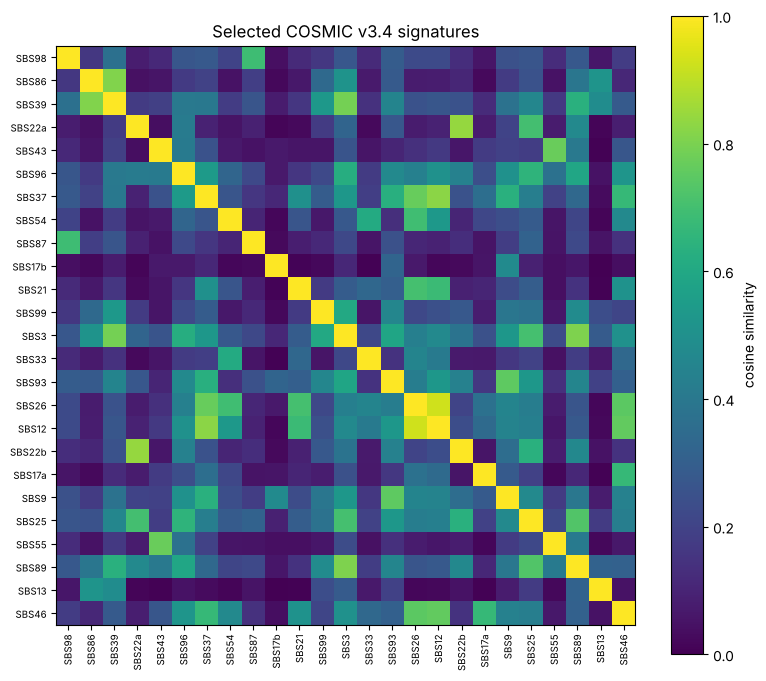

off-diagonal cosine: mean=0.264, max=0.928


In [4]:
S = cosmic[ORTHOGONAL_SIGNATURES].values
Sn = S / np.linalg.norm(S, axis=0)
cos = Sn.T @ Sn
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cos, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(25)); ax.set_xticklabels(ORTHOGONAL_SIGNATURES, rotation=90, fontsize=7)
ax.set_yticks(range(25)); ax.set_yticklabels(ORTHOGONAL_SIGNATURES, fontsize=7)
fig.colorbar(im, ax=ax, label="cosine similarity")
ax.set_title("Selected COSMIC v3.4 signatures")
plt.tight_layout(); plt.show()
off = cos[~np.eye(25, dtype=bool)]
print(f"off-diagonal cosine: mean={off.mean():.3f}, max={off.max():.3f}")

## 3. Simulation functions

In [5]:
def total_mutation_range(cancer_type=CANCER_TYPE):
    if cancer_type == "manual":
        return MANUAL_RANGE
    return BURDEN_RANGES[cancer_type]


def simulate_catalogue(n_signatures, noise_level, n_samples=N_SAMPLES, p_present=P_PRESENT,
                       cancer_type=CANCER_TYPE, rng=None):
    '''Simulate one SBS catalogue following Section 3.1.

    Returns
    -------
    X       : DataFrame (96 x n_samples)  noisy mutation counts (input to NMF)
    X_clean : DataFrame (96 x n_samples)  counts before noise
    W       : DataFrame (96 x n_signatures) true signatures (columns sum to 1)
    H       : DataFrame (n_signatures x n_samples) true exposures, in mutation counts
    noise   : DataFrame (96 x n_samples)  the added Poisson noise
    '''
    rng = np.random.default_rng() if rng is None else rng
    sig_names = ORTHOGONAL_SIGNATURES[:n_signatures]
    W = cosmic[sig_names]                                   # 96 x n

    # (2) total SBS per sample: uniform on the log scale
    lo, hi = total_mutation_range(cancer_type)
    totals = np.round(np.exp(rng.uniform(np.log(lo), np.log(hi), n_samples))).astype(int)

    # (3) presence of each signature, Bernoulli(p); every sample keeps at least one signature
    present = rng.random((n_signatures, n_samples)) < p_present
    empty = ~present.any(axis=0)
    present[rng.integers(0, n_signatures, empty.sum()), np.where(empty)[0]] = True

    # (4) contribution of each present signature: uniform, normalised per sample
    contrib = rng.uniform(*CONTRIB_RANGE, size=(n_signatures, n_samples)) * present
    contrib /= contrib.sum(axis=0, keepdims=True)

    # (5) combine with the signature profiles -> integer counts per sample
    H = contrib * totals                                    # exposures in mutation counts
    if COUNT_MODEL == "round":
        X_clean = np.rint(W.values @ H).astype(int)
    else:
        X_clean = np.column_stack([
            rng.multinomial(totals[j], W.values @ contrib[:, j]) for j in range(n_samples)
        ])

    # (6) Poisson noise: per sample, Poisson(noise_level * total) extra mutations,
    #     spread uniformly at random over the 96 channels
    n_noise = rng.poisson(noise_level * X_clean.sum(axis=0))
    n_types = W.shape[0]
    noise = np.column_stack([rng.multinomial(k, np.full(n_types, 1 / n_types)) for k in n_noise])
    X = X_clean + noise

    samples = [f"sample_{j + 1:03d}" for j in range(n_samples)]
    as_df = lambda a, idx: pd.DataFrame(a, index=idx, columns=samples)
    return dict(
        X=as_df(X, W.index), X_clean=as_df(X_clean, W.index), noise=as_df(noise, W.index),
        W=W.copy(), H=as_df(H, sig_names),
    )

## 4. Generate all 9 experimental conditions

In [6]:
os.makedirs(OUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)
datasets = {}
summary = []
for k in N_SIGNATURES_LIST:
    for noise in NOISE_LEVELS:
        d = simulate_catalogue(k, noise, rng=rng)
        datasets[(k, noise)] = d
        tag = f"k{k}_noise{int(noise * 100)}pct"
        d["X"].to_csv(f"{OUT_DIR}/X_{tag}.csv")         # NMF input, 96 x samples
        d["W"].to_csv(f"{OUT_DIR}/W_true_{tag}.csv")    # ground-truth signatures
        d["H"].to_csv(f"{OUT_DIR}/H_true_{tag}.csv")    # ground-truth exposures
        tot = d["X_clean"].sum(axis=0)
        summary.append(dict(
            n_signatures=k, noise=noise,
            mean_sigs_per_sample=(d["H"] > 0).sum(axis=0).mean(),
            expected_sigs_per_sample=k * P_PRESENT,
            median_total=int(tot.median()), min_total=int(tot.min()), max_total=int(tot.max()),
            realised_noise_frac=d["noise"].values.sum() / d["X_clean"].values.sum(),
        ))
summary = pd.DataFrame(summary)
summary

,n_signatures,noise,mean_sigs_per_sample,expected_sigs_per_sample,median_total,min_total,max_total,realised_noise_frac
0,8,0.02,3.120,3.2,222,39,992,0.020208
1,8,0.04,3.215,3.2,199,36,1000,0.039935
2,8,0.06,3.155,3.2,177,36,981,0.058225
3,15,0.02,5.890,6.0,216,38,997,0.019732
4,15,0.04,6.190,6.0,207,34,975,0.040322
5,15,0.06,5.835,6.0,229,32,981,0.061087
6,25,0.02,9.795,10.0,237,35,987,0.019982
7,25,0.04,9.910,10.0,255,37,1000,0.039895
8,25,0.06,9.795,10.0,230,37,982,0.060750


Files written (one X / W_true / H_true triple per condition):

In [7]:
sorted(os.listdir(OUT_DIR))

['H_true_k15_noise2pct.csv',
 'H_true_k15_noise4pct.csv',
 'H_true_k15_noise6pct.csv',
 'H_true_k25_noise2pct.csv',
 'H_true_k25_noise4pct.csv',
 'H_true_k25_noise6pct.csv',
 'H_true_k8_noise2pct.csv',
 'H_true_k8_noise4pct.csv',
 'H_true_k8_noise6pct.csv',
 'W_true_k15_noise2pct.csv',
 'W_true_k15_noise4pct.csv',
 'W_true_k15_noise6pct.csv',
 'W_true_k25_noise2pct.csv',
 'W_true_k25_noise4pct.csv',
 'W_true_k25_noise6pct.csv',
 'W_true_k8_noise2pct.csv',
 'W_true_k8_noise4pct.csv',
 'W_true_k8_noise6pct.csv',
 'X_k15_noise2pct.csv',
 'X_k15_noise4pct.csv',
 'X_k15_noise6pct.csv',
 'X_k25_noise2pct.csv',
 'X_k25_noise4pct.csv',
 'X_k25_noise6pct.csv',
 'X_k8_noise2pct.csv',
 'X_k8_noise4pct.csv',
 'X_k8_noise6pct.csv']

## 5. Sanity checks and plots

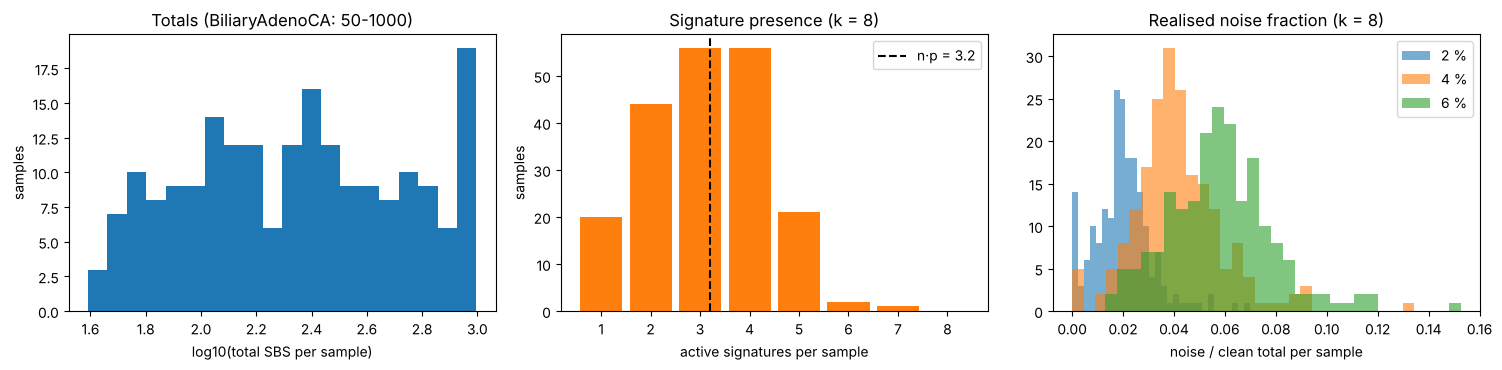

In [8]:
# (a) totals are log-uniform; (b) noise fraction matches the requested level
d = datasets[(8, 0.02)]
tot = d["X_clean"].sum(axis=0)
lo, hi = total_mutation_range()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(np.log10(tot), bins=20, color="tab:blue")
axes[0].set(xlabel="log10(total SBS per sample)", ylabel="samples",
            title=f"Totals ({CANCER_TYPE}: {lo}-{hi})")
axes[1].hist((d["H"] > 0).sum(axis=0), bins=np.arange(0.5, 9.5), color="tab:orange", rwidth=0.85)
axes[1].axvline(8 * P_PRESENT, color="k", ls="--", label=f"n·p = {8 * P_PRESENT:.1f}")
axes[1].set(xlabel="active signatures per sample", ylabel="samples", title="Signature presence (k = 8)")
axes[1].legend()
for noise in NOISE_LEVELS:
    dd = datasets[(8, noise)]
    frac = dd["noise"].sum(axis=0) / dd["X_clean"].sum(axis=0)
    axes[2].hist(frac, bins=30, alpha=0.6, label=f"{int(noise * 100)} %")
axes[2].set(xlabel="noise / clean total per sample", title="Realised noise fraction (k = 8)")
axes[2].legend()
plt.tight_layout(); plt.show()

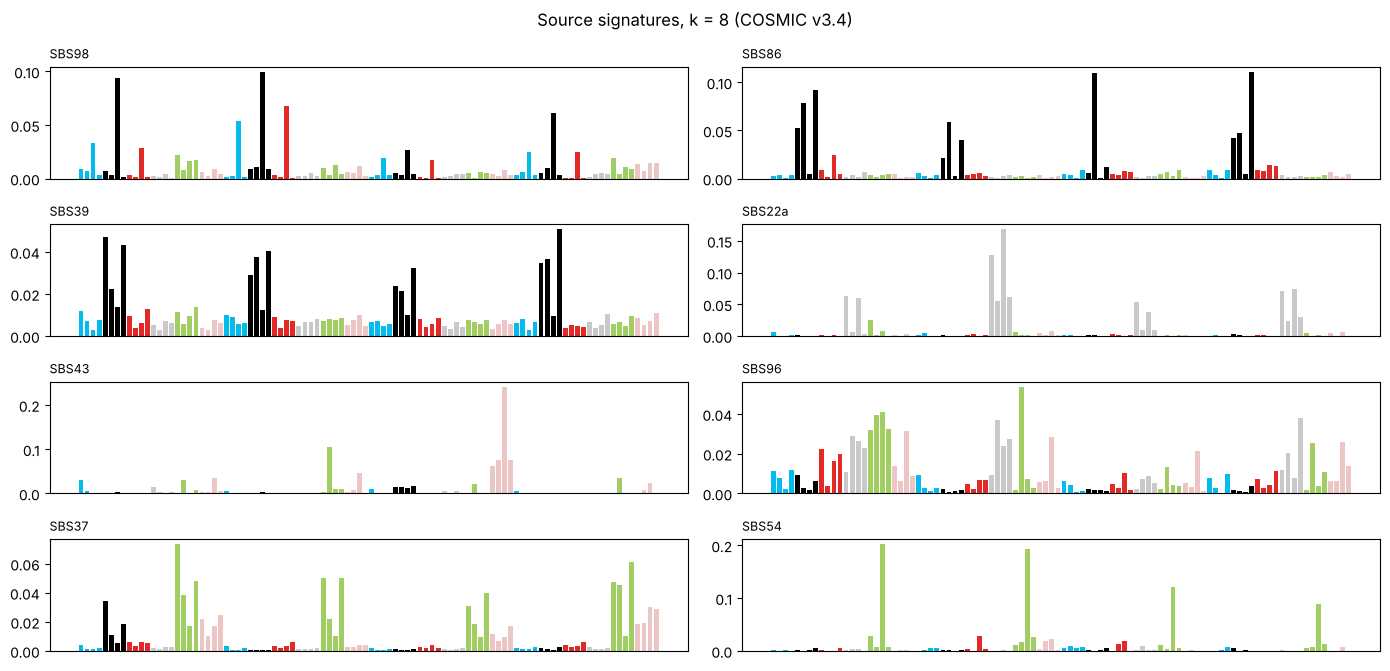

In [9]:
# 96-channel profiles: the 8 source signatures
CHANNEL_COLOURS = {"C>A": "#03BCEE", "C>G": "#010101", "C>T": "#E32926",
                   "T>A": "#CAC9C9", "T>C": "#A1CE63", "T>G": "#EBC6C4"}

def channel_colours(index):
    return [CHANNEL_COLOURS[t[2:5]] for t in index]

def plot_profiles(df, title, ncols=2):
    n = df.shape[1]
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 1.7 * nrows), sharex=True, squeeze=False)
    cols = channel_colours(df.index)
    for ax, name in zip(axes.flat, df.columns):
        ax.bar(range(len(df)), df[name], color=cols, width=0.8)
        ax.set_title(name, fontsize=9, loc="left"); ax.set_xticks([])
    for ax in axes.flat[n:]:
        ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_profiles(datasets[(8, 0.02)]["W"], "Source signatures, k = 8 (COSMIC v3.4)")

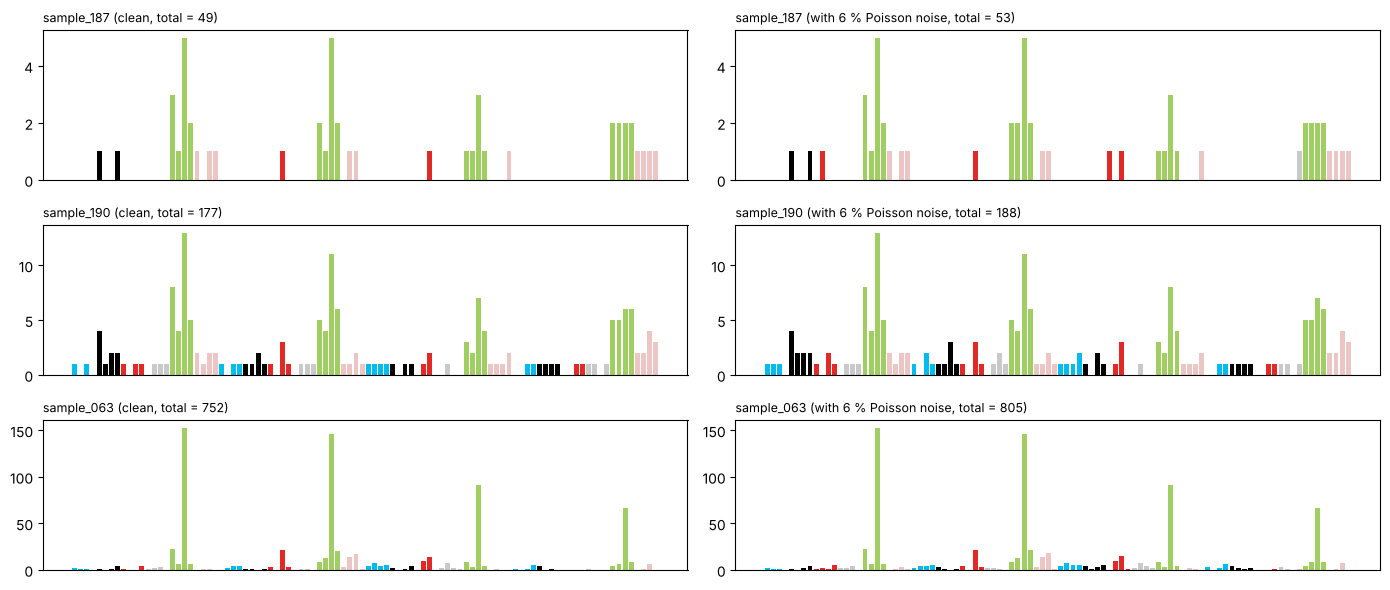

In [10]:
# A few simulated samples: clean vs noisy (k = 8, 6 % noise)
d = datasets[(8, 0.06)]
idx = d["X"].sum(axis=0).sort_values().index[[10, 100, 190]]
fig, axes = plt.subplots(3, 2, figsize=(14, 6), sharex=True)
cols = channel_colours(d["X"].index)
for r, s in enumerate(idx):
    for c, (name, M) in enumerate([("clean", d["X_clean"]), ("with 6 % Poisson noise", d["X"])]):
        axes[r, c].bar(range(96), M[s], color=cols, width=0.8)
        axes[r, c].set_title(f"{s} ({name}, total = {int(M[s].sum())})", fontsize=9, loc="left")
        axes[r, c].set_xticks([])
plt.tight_layout(); plt.show()

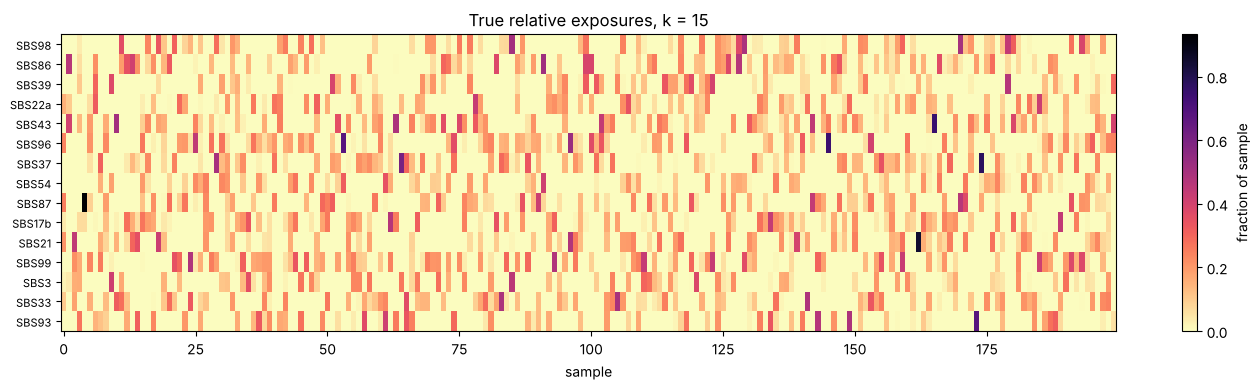

In [11]:
# Exposure matrix H (fraction of each sample's mutations per signature), k = 15
H = datasets[(15, 0.02)]["H"]
Hf = H / H.sum(axis=0)
fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(Hf.values, aspect="auto", cmap="magma_r")
ax.set_yticks(range(len(Hf))); ax.set_yticklabels(Hf.index, fontsize=8)
ax.set_xlabel("sample"); ax.set_title("True relative exposures, k = 15")
fig.colorbar(im, ax=ax, label="fraction of sample")
plt.tight_layout(); plt.show()

In [12]:
# Ground-truth consistency: X_clean vs W @ H differs only by rounding (COUNT_MODEL='round'); X adds the Poisson noise
for (k, noise), d in datasets.items():
    rec = d["W"].values @ d["H"].values
    rel = np.linalg.norm(d["X_clean"].values - rec) / np.linalg.norm(d["X_clean"].values)
    rel_noisy = np.linalg.norm(d["X"].values - rec) / np.linalg.norm(d["X"].values)
    print(f"k={k:2d} noise={noise:.2f}  ||X_clean - WH||/||X_clean|| = {rel:.3f}   ||X - WH||/||X|| = {rel_noisy:.3f}")

k= 8 noise=0.02  ||X_clean - WH||/||X_clean|| = 0.037   ||X - WH||/||X|| = 0.050
k= 8 noise=0.04  ||X_clean - WH||/||X_clean|| = 0.043   ||X - WH||/||X|| = 0.069
k= 8 noise=0.06  ||X_clean - WH||/||X_clean|| = 0.044   ||X - WH||/||X|| = 0.079
k=15 noise=0.02  ||X_clean - WH||/||X_clean|| = 0.042   ||X - WH||/||X|| = 0.057
k=15 noise=0.04  ||X_clean - WH||/||X_clean|| = 0.045   ||X - WH||/||X|| = 0.074
k=15 noise=0.06  ||X_clean - WH||/||X_clean|| = 0.044   ||X - WH||/||X|| = 0.086
k=25 noise=0.02  ||X_clean - WH||/||X_clean|| = 0.045   ||X - WH||/||X|| = 0.061
k=25 noise=0.04  ||X_clean - WH||/||X_clean|| = 0.043   ||X - WH||/||X|| = 0.074
k=25 noise=0.06  ||X_clean - WH||/||X_clean|| = 0.046   ||X - WH||/||X|| = 0.090


## 6. Notes

* **Using the data for NMF.** `X_*.csv` is the input catalogue (96 × samples). For Wasserstein NMF, normalise
  each column to sum to 1 first, as described in Section 3.2.1. `W_true_*.csv` and `H_true_*.csv` are the
  ground truth for the cosine-similarity / Hungarian matching in Section 3.3.
* **Interpretation choices.** The report does not say how counts are drawn from the mixture or how noise is
  spread over channels. Here the clean counts are the product W·H rounded to integers (set
  `COUNT_MODEL = "multinomial"` to draw them instead, which adds much more sampling noise than the 2-6 %
  Poisson noise), and the Poisson noise count is spread uniformly over the 96 channels.
* **Signature ranking.** The 25 signatures are copied from the report. The exact orthogonality criterion
  used to rank them is not specified, so the list is hard-coded rather than recomputed.